# Resultados del benchmark y análisis estadístico

Estas celdas **regeneran todas las tablas y figuras** a partir de `results/e2/corridas/<modelo>_s<semilla>/test_por_imagen.csv` y `results/e2/corridas.csv`. El análisis sigue `preregistro_E2.md` §5 sin cambiar ninguna regla.

**Cómo se calcula.** Cada imagen de test tiene un F1 de instancia (tornillos bien delimitados frente a falsos y perdidos, con IoU de máscara ≥ 0.5). Las 108 imágenes de test pertenecen a 14 grupos de escena, que son las unidades independientes. El F1 de un grupo es el promedio de sus imágenes; luego se promedian las 5 semillas. Cada modelo queda con 14 números, y todas las pruebas comparan esos 14 pares.

In [1]:
import runpy, sys, json
from pathlib import Path
import pandas as pd
pd.set_option("display.width", 160)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "results/e2/analisis"
sys.argv = ["analisis_e2.py", str(ROOT / "results/e2/corridas"), str(ROOT / "results/e2/corridas.csv"), str(OUT)]
import io, contextlib
_buf = io.StringIO()
with contextlib.redirect_stdout(_buf):
    _ = runpy.run_path(str(ROOT / "analisis_e2.py"), run_name="__main__")  # el script imprime sus resultados; abajo se muestran ordenados

## Control de calidad del cálculo

El F1 por grupo recalculado desde los CSV por imagen debe coincidir con la columna `test_F1_grupo` de `corridas.csv` (la que escribió el código de entrenamiento).

In [2]:
v = pd.read_csv(OUT / "verificacion_vs_corridas_csv.csv", index_col=0)
print("Diferencia absoluta máxima:", float(v.dif_abs.max()))
v.round(4)

Diferencia absoluta máxima: 1.1102230246251563e-16


,corridas_csv,recalculado,dif_abs
modelo,,,
cascade,0.7234,0.7234,0.0
clasico,0.0179,0.0179,0.0
condinst,0.6069,0.6069,0.0
htc,0.7236,0.7236,0.0
mask2former,0.5452,0.5452,0.0
maskrcnn,0.7259,0.7259,0.0
msrcnn,0.7162,0.7162,0.0
pointrend,0.7009,0.7009,0.0
solov2,0.2308,0.2308,0.0


## Tabla principal (F1 por grupo en test)

Media de las 5 semillas y desviación estándar entre semillas. «Vacío» (máscara vacía) tiene F1 = 0 por construcción.

In [3]:
tab = pd.read_csv(OUT / "tabla_principal.csv", index_col=0)
corr = pd.read_csv(ROOT / "results/e2/corridas.csv")
corr = corr[corr.semilla.between(42, 46)]
extra = corr.groupby("modelo").agg(F1_grupo_val=("val_F1_grupo", "mean"), parametros_M=("parametros", lambda s: s.iloc[0] / 1e6),
                                   min_por_corrida=("s_total", lambda s: s.mean() / 60), mejor_epoca_media=("mejor_epoca", "mean"))
tab.join(extra).round(3)

,F1_grupo_test_media,DE_entre_semillas,F1_grupo_val,parametros_M,min_por_corrida,mejor_epoca_media
modelo,,,,,,
maskrcnn,0.726,0.012,0.783,43.922,17.941,5.2
htc,0.724,0.017,0.756,77.152,27.432,4.4
cascade,0.723,0.006,0.764,77.021,23.267,5.6
msrcnn,0.716,0.010,0.792,60.230,17.717,5.4
pointrend,0.701,0.019,0.784,55.755,17.465,5.6
yolov7,0.638,0.030,0.704,37.866,24.631,5.0
condinst,0.607,0.009,0.720,33.982,17.735,4.8
yolo26,0.569,0.020,0.645,3.083,8.072,5.8
yolov8,0.566,0.032,0.627,3.391,4.613,5.6


## RQ1: ¿algún modelo del Top 10 supera al mejor baseline fuerte por al menos δ = 0.20?

El comparador se eligió **por F1 de grupo en validación**, antes de mirar test (preregistro §5): entre Mask R-CNN, YOLOv8, SOLOv2 y el clásico.

- **Wilcoxon de rangos con signo (unilateral):** ordena las 14 diferencias por tamaño y suma los rangos de las positivas; no supone normalidad.
- **Holm:** con 10 contrastes se corrige el riesgo de falsos positivos: el menor p se multiplica por 10, el siguiente por 9, etc.
- **IC 95 % bootstrap:** se remuestrean los 14 grupos con reemplazo 10 000 veces y se toman los percentiles 2.5 y 97.5 de la diferencia media.
- **Regla de decisión** (preregistro §5): *significativa y relevante* si p Holm < 0.05, diferencia ≥ δ y límite inferior del IC > 0; *equivalente* si el IC cae dentro de ±δ; si no, *no concluyente*.

In [4]:
rq1 = pd.read_csv(OUT / "rq1_top10_vs_baseline.csv")
print("Mejor baseline fuerte por val:", corr.groupby("modelo").val_F1_grupo.mean()[["maskrcnn", "yolov8", "solov2", "clasico"]].round(3).to_dict())
rq1.round(4)

Mejor baseline fuerte por val: {'maskrcnn': 0.783, 'yolov8': 0.627, 'solov2': 0.466, 'clasico': 0.011}


,modelo,F1_modelo,F1_base,dif_media,dif_mediana,ic95_lo,ic95_hi,p_wilcoxon,p_t_sensib,shapiro_p,grupos_mejores,grupos_peores,p_holm,decision
0,htc,0.7236,0.7259,-0.0023,-0.0001,-0.0166,0.0117,0.5693,0.6183,0.0873,6,7,1.0,equivalente
1,cascade,0.7234,0.7259,-0.0025,-0.0064,-0.0217,0.0172,0.6999,0.5934,0.5951,5,8,1.0,equivalente
2,msrcnn,0.7162,0.7259,-0.0097,-0.0089,-0.0274,0.0072,0.8606,0.8458,0.8391,5,8,1.0,equivalente
3,pointrend,0.7009,0.7259,-0.0250,-0.0130,-0.0553,-0.0001,0.9335,0.9448,0.0295,4,9,1.0,equivalente
4,yolov7,0.6377,0.7259,-0.0882,-0.0796,-0.1477,-0.0244,0.9877,0.9900,0.7427,2,12,1.0,equivalente
5,condinst,0.6069,0.7259,-0.1190,-0.0927,-0.1764,-0.0665,0.9993,0.9993,0.1373,0,13,1.0,equivalente
6,yolo26,0.5690,0.7259,-0.1569,-0.1472,-0.2121,-0.1036,0.9993,1.0000,0.7381,0,13,1.0,no concluyente
7,mask2former,0.5452,0.7259,-0.1806,-0.1854,-0.2421,-0.1232,1.0000,1.0000,0.3704,0,14,1.0,no concluyente
8,yolo11,0.5296,0.7259,-0.1963,-0.1955,-0.2512,-0.1418,1.0000,1.0000,0.9773,0,14,1.0,no concluyente
9,yolov9,0.4046,0.7259,-0.3212,-0.3209,-0.4080,-0.2379,1.0000,1.0000,0.9934,0,14,1.0,no concluyente


**Lectura.** Ningún modelo del Top 10 supera al baseline. La etiqueta «equivalente» sale de aplicar la regla literalmente con un δ muy grande (0.20): incluye modelos claramente peores (por ejemplo CondInst, que pierde en 13 de 14 grupos). Hay que leerla junto con la dirección y el IC: HTC, Cascade, MS R-CNN y PointRend son indistinguibles de Mask R-CNN; YOLOv7 y CondInst son peores por 0.09–0.12; YOLO26, Mask2Former, YOLO11 y YOLOv9 son peores por 0.16–0.32. La regla de decisión no se modificó.

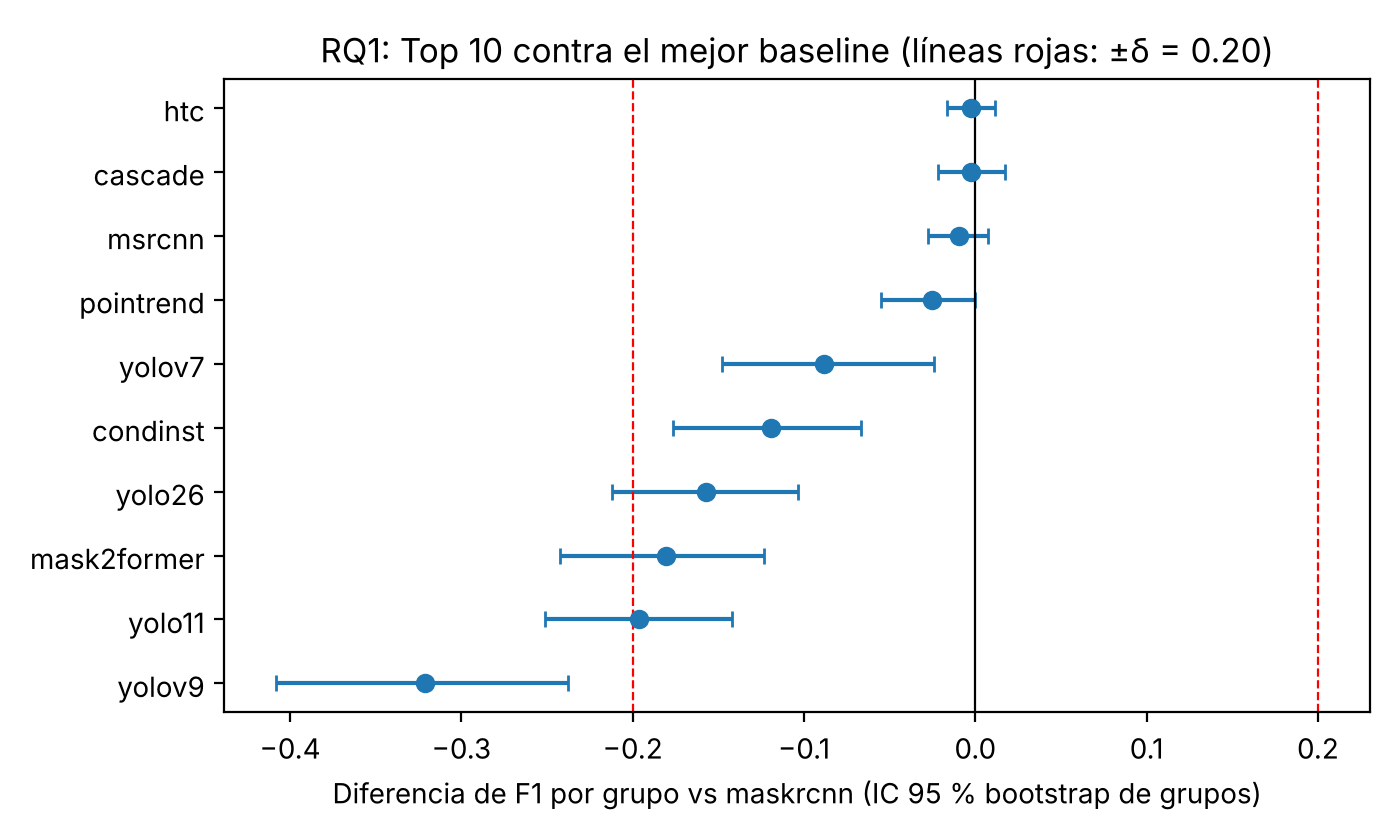

In [5]:
from IPython.display import Image
Image(filename=str(OUT / "rq1_diferencias.png"))

## RQ2: familia de dos etapas (R) frente a prototipos (P)

R = Cascade, HTC, PointRend, MS R-CNN. P = YOLOv7, YOLOv9, YOLO26, YOLO11. Para cada grupo se compara la media de los 4 modelos R con la de los 4 modelos P; Wilcoxon bilateral, α = 0.05, un solo contraste.

In [6]:
rq2 = json.load(open(OUT / "rq2_R_vs_P.json"))
pd.Series(rq2).round(5)

media_R            0.71601
media_P            0.53522
dif_media          0.18079
dif_mediana        0.18999
ic95_lo            0.13375
ic95_hi            0.22228
p_wilcoxon         0.00024
grupos_R_mejor    13.00000
shapiro_p          0.33246
p_t_sensib         0.00000
dtype: float64

**Lectura.** R supera a P en el protocolo del E2. **Cuidado con la causa:** familia, marco de software (MMDetection frente a ultralytics y repos oficiales), tamaño de lote efectivo y preentrenamiento están mezclados. La prueba muestra que la diferencia existe; no identifica la arquitectura como causa.

## Comparación global

Friedman (14 modelos, 14 grupos como bloques) y distancia crítica de Nemenyi: dos modelos difieren si sus rangos medios se separan más que la distancia crítica.

In [7]:
fr = json.load(open(OUT / "friedman.json"))
print(fr)
pd.read_csv(OUT / "friedman_rangos.csv", index_col=0).round(2).T

{'chi2': 139.56300225008042, 'p': 2.5746992498356707e-23, 'k': 14, 'n_grupos': 14, 'CD_nemenyi': 5.302535248713323}


modelo,maskrcnn,htc,msrcnn,cascade,pointrend,yolov7,condinst,yolo26,yolov8,mask2former,yolo11,yolov9,solov2,clasico
rango_medio,2.82,2.96,3.39,3.57,4.11,6.93,7.32,8.71,9.32,9.43,9.64,11.43,11.79,13.57


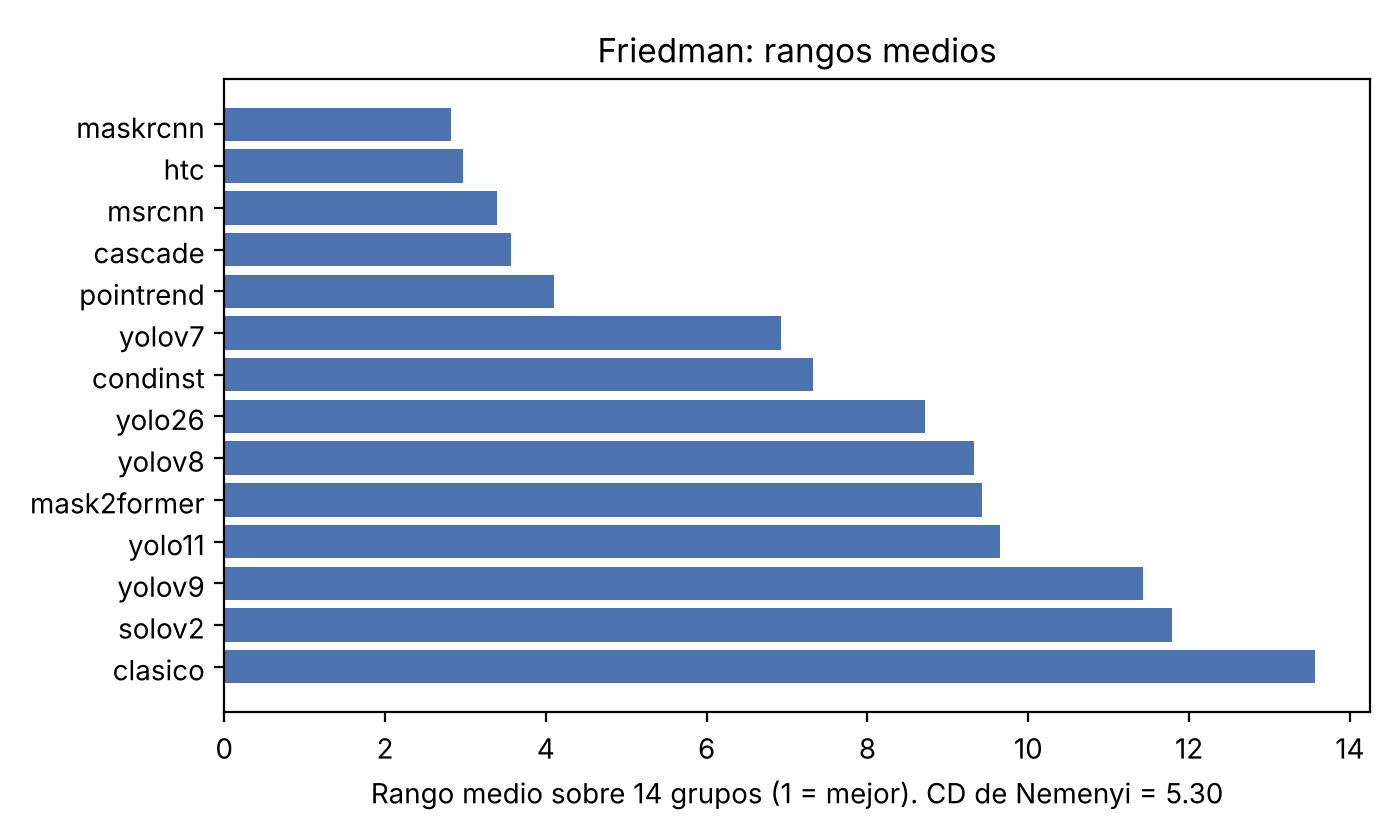

In [8]:
Image(filename=str(OUT / "friedman_rangos.png"))

## Comparaciones por pares (exploratorio)

91 pares, Wilcoxon bilateral con Benjamini–Hochberg. Se muestran los pares que **no** son significativos tras la corrección.

In [9]:
p = pd.read_csv(OUT / "pares_exploratorio_BH.csv")
print("Pares con p ajustado < 0.05:", int((p.p_BH < 0.05).sum()), "de", len(p))
p[p.p_BH >= 0.05].sort_values("p_BH").round(4)

Pares con p ajustado < 0.05: 66 de 91


,a,b,dif_media,p,p_BH
16,yolov7,cascade,-0.0857,0.0419,0.0569
0,mask2former,yolov7,-0.0925,0.0494,0.0662
50,yolo11,condinst,-0.0773,0.0546,0.0720
22,yolov7,yolov8,0.0719,0.0580,0.0754
82,condinst,yolov8,0.0411,0.0597,0.0766
34,yolov9,solov2,0.1739,0.1005,0.1271
14,yolov7,yolo26,0.0688,0.1189,0.1482
72,pointrend,maskrcnn,-0.0250,0.1330,0.1613
70,pointrend,msrcnn,-0.0153,0.1330,0.1613
56,cascade,pointrend,0.0225,0.1361,0.1630


## Estabilidad entre semillas

El F1 de test por semilla muestra qué modelos son inestables. Mask2Former tiene una corrida con colapso (semilla 46). No se excluye: el preregistro solo permite excluir por fallo técnico.

In [10]:
ps = pd.read_csv(OUT / "f1_grupo_por_semilla.csv")
s = ps.groupby(["modelo", "semilla"]).f1_grupo.mean().unstack().round(3)
s["rango"] = (s.max(axis=1) - s.min(axis=1)).round(3)
s.sort_values("rango", ascending=False)

semilla,42,43,44,45,46,rango
modelo,,,,,,
mask2former,0.530,0.612,0.659,0.621,0.304,0.355
yolo11,0.469,0.523,0.505,0.590,0.561,0.121
yolov9,0.408,0.350,0.422,0.451,0.392,0.101
yolov8,0.512,0.565,0.593,0.574,0.585,0.081
yolov7,0.672,0.624,0.601,0.625,0.666,0.071
solov2,0.236,0.197,0.248,0.247,0.225,0.051
pointrend,0.720,0.701,0.714,0.672,0.698,0.048
yolo26,0.551,0.552,0.594,0.587,0.561,0.043
htc,0.699,0.736,0.712,0.739,0.733,0.040


## Mejor época

Con 6 épocas para todos, un modelo cuya mejor época es la última (6) puede estar subentrenado (regla de parada del preregistro §4). Número de semillas (de 5) con mejor época igual a 6:

In [11]:
(corr.assign(ultima=corr.mejor_epoca == 6).groupby("modelo").ultima.sum().astype(int)).sort_values(ascending=False).to_frame("semillas_con_mejor_epoca_6")

,semillas_con_mejor_epoca_6
modelo,
mask2former,4
yolo11,4
yolo26,4
yolov8,4
maskrcnn,3
cascade,3
yolov9,3
pointrend,3
msrcnn,2
